Jumlah cluster terbentuk : 2
Banyaknya sampel noise   : 2
Adjusted Rand Index (ARI): 0.5638
Normalized Mutual Info   : 0.7175


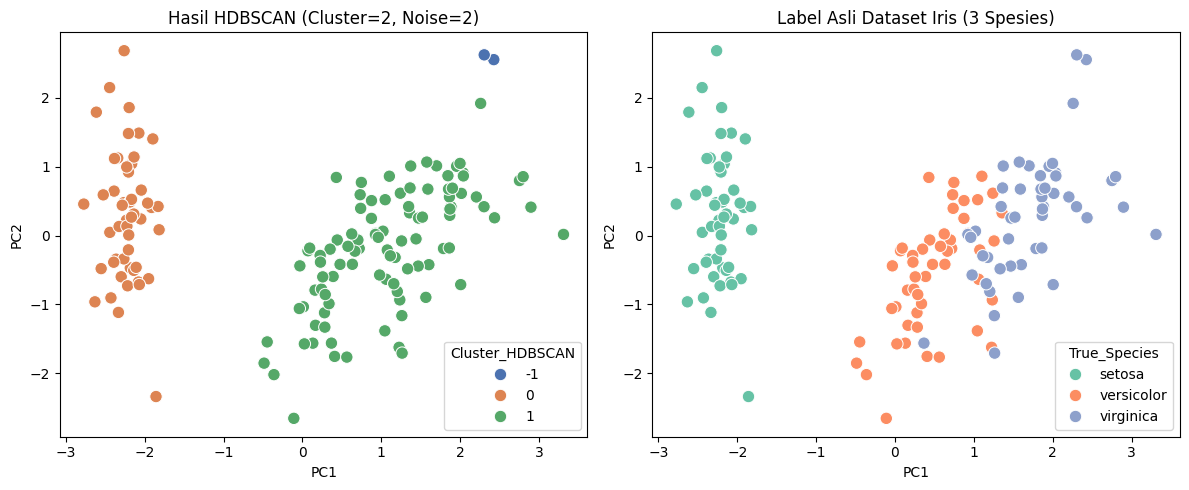

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Memuat dataset Iris dan melakukan standardisasi fitur
iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)
y_true = iris.target

# 2. Menjalankan klasterisasi HDBSCAN
hdb = HDBSCAN(min_cluster_size=5)
clusters = hdb.fit_predict(X_scaled)

# 3. Melaporkan jumlah cluster dan banyaknya noise
n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)
print(f"Jumlah cluster terbentuk : {n_clusters}")
print(f"Banyaknya sampel noise   : {n_noise}")
print(f"Adjusted Rand Index (ARI): {adjusted_rand_score(y_true, clusters):.4f}")
print(f"Normalized Mutual Info   : {normalized_mutual_info_score(y_true, clusters):.4f}")

# 4. Reduksi dimensi ke 2D menggunakan PCA untuk visualisasi
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_plot = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_plot['Cluster_HDBSCAN'] = clusters
df_plot['True_Species'] = [iris.target_names[i] for i in y_true]

# 5. Visualisasi hasil clustering vs label asli
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df_plot, x='PC1', y='PC2', hue='Cluster_HDBSCAN', palette='deep', s=80, ax=axes[0])
axes[0].set_title(f'Hasil HDBSCAN (Cluster={n_clusters}, Noise={n_noise})')

sns.scatterplot(data=df_plot, x='PC1', y='PC2', hue='True_Species', palette='Set2', s=80, ax=axes[1])
axes[1].set_title('Label Asli Dataset Iris (3 Spesies)')

plt.tight_layout()
plt.show()